# BMI Category Classification

I used height and weight to predict BMI categories and compared Gaussian Naive Bayes, LDA, and QDA on a stratified validation split.

### Basic Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

## Data Preperation

#### Ingestion

In [2]:
dataset = pd.read_csv('bmi.csv')

# Print the first 10 rows of the dataset
dataset.head(10)

,Gender,Height,Weight,Index
0,Male,174,96,Obese
1,Male,189,87,Normal
2,Female,185,110,Obese
3,Female,195,104,Overweight
4,Male,149,61,Overweight
5,Male,189,104,Overweight
6,Male,147,92,Extremely Obese
7,Male,154,111,Extremely Obese
8,Male,174,90,Overweight
9,Female,169,103,Obese


#### Cleaning

In [3]:
num_missing_vals = dataset.isnull().sum().sum()
print("Number of missing values:", num_missing_vals)
dataset.dropna(inplace=True)
dataset.drop(columns=['Gender'], inplace=True)
dataset.head(10)

Number of missing values: 0


,Height,Weight,Index
0,174,96,Obese
1,189,87,Normal
2,185,110,Obese
3,195,104,Overweight
4,149,61,Overweight
5,189,104,Overweight
6,147,92,Extremely Obese
7,154,111,Extremely Obese
8,174,90,Overweight
9,169,103,Obese


#### Splitting

In [4]:
y_data = pd.Series(dataset['Index'])
x_data = dataset.drop(columns=['Index'])

# Keep class proportions similar in the training and validation sets.
x_data, y_data = x_data.to_numpy(), y_data.to_numpy()
x_train, x_val, y_train, y_val = train_test_split(x_data, y_data, test_size=0.2, random_state=0, stratify=y_data)
# Think of how you would implement the line above using Numpy as you may be asked about that.

#### Exploratory Analysis

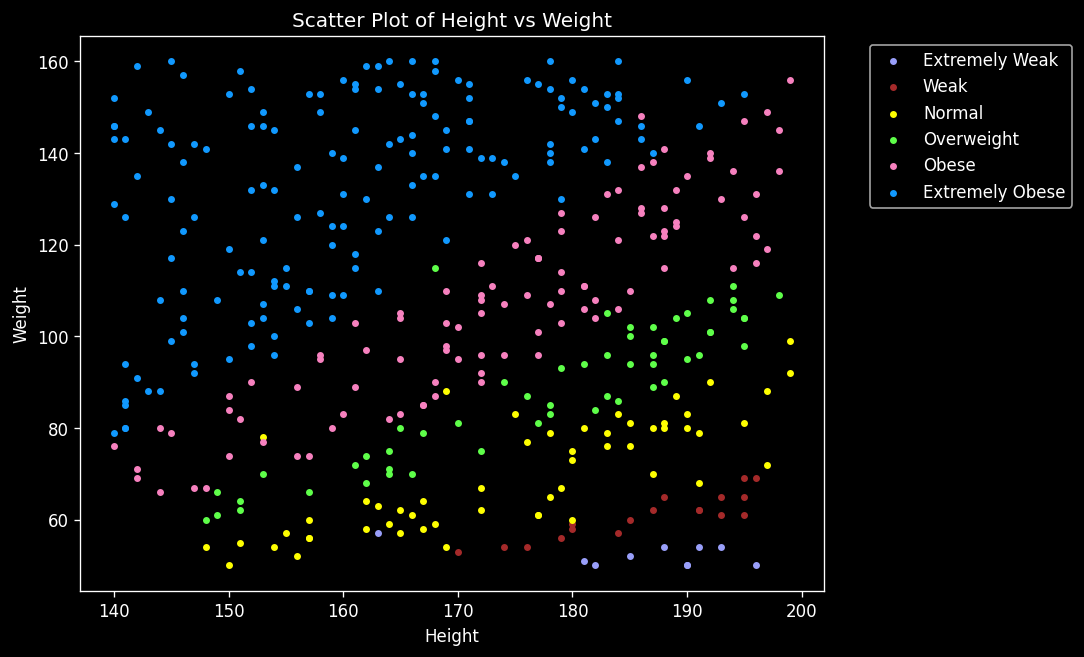

In [5]:
# Define distinctive colors for the six classes
classes = ['Extremely Weak', 'Weak', 'Normal', 'Overweight', 'Obese', 'Extremely Obese']
colors = ['#999FFA', '#a52a2a', '#ffff00', '#5fff4a', '#f781bf', '#1199ff',]

# Initiate plot
plt.style.use('dark_background')            
plt.figure(figsize=(8, 6), dpi=120)

# Make a scatter plot for each class
for i, label in enumerate(classes):
    x_train_class = x_train[y_train == label]
    plt.scatter(x_train_class[:, 0], x_train_class[:, 1], color=colors[i], label=classes[i], s=10)

plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Scatter Plot of Height vs Weight')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

The least represented BMI categories have fewer examples for the model to learn from. The scatter plot shows where the categories overlap.

## Model Building & Evaluation

In [7]:

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score

from BayesClassifier import BayesClassifier

#### Gaussian Naive Bayes

In [8]:
# Initiate
gnb_model = BayesClassifier(mode='Naive')
# Fit
gnb_model.fit(x_train, y_train)
# Predict
gnb_y_pred = gnb_model.predict(x_val)
# Evalute
gnb_accuracy = gnb_model.score(x_val, y_val)
print("Gaussian Naive Bayes Accuracy:", gnb_accuracy)

Gaussian Naive Bayes Accuracy: 0.77


In [15]:
gnb_model.covs.shape

(6, 2, 2)

#### Linear Discriminant Analysis

In [18]:
# Initiate
lda_model = BayesClassifier(mode='LDA')
# Fit
lda_model.fit(x_train, y_train)
# Predict
lda_y_pred = lda_model.predict(x_val)
# Evaluate
lda_accuracy = lda_model.score(x_val, y_val)
print("Linear Discriminant Analysis Accuracy:", lda_accuracy)

Linear Discriminant Analysis Accuracy: 0.84


In [23]:
lda_model.weighted_cov

array([[197.69354533, 183.12121826],
       [183.12121826, 351.50009002]])

#### Quadratic Discriminant Analysis

In [11]:
qda_model = BayesClassifier(mode='QDA')
qda_model.fit(x_train, y_train)
qda_y_pred = qda_model.predict(x_val)
qda_accuracy = qda_model.score(x_val, y_val)
print("Quadratic Discriminant Analysis Accuracy:", qda_accuracy)

Quadratic Discriminant Analysis Accuracy: 0.93


#### Visualize Model

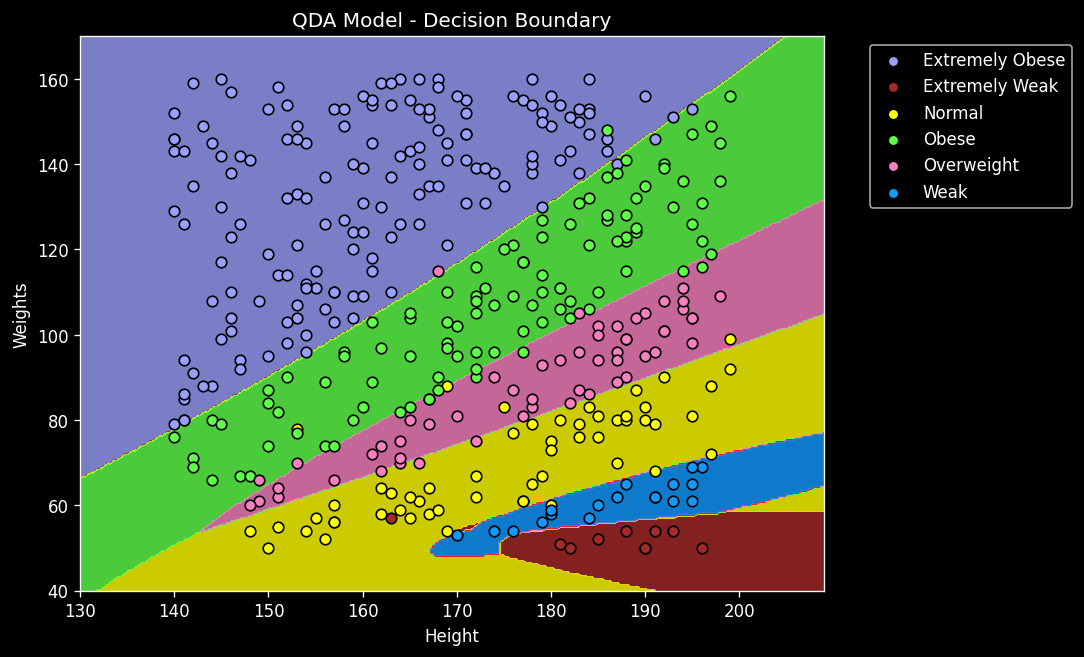

In [12]:
import matplotlib

model = qda_model

# Training data used for the decision boundary plot.
h = np.linspace(np.min(x_train[:, 0])-10, np.max(x_train[:, 0])+10, 300)
w = np.linspace(np.min(x_train[:, 1])-10, np.max(x_train[:, 1])+10, 300)
x, y = np.meshgrid(h, w)

# For each pair (h, w) in the grid predict the labels by inputing (grid_size, 2) array of (h, w) into the model
z_labels = qda_model.predict(np.c_[x.ravel(), y.ravel()])               # flatten x, y then concatenate
# map array of labels to array of integers to represent different contour levels (colors)
z = np.array([list(qda_model.labels).index(label) for label in z_labels])
# reshape z into a grid
z = z.reshape(x.shape)

# Plot setupt
plt.style.use('dark_background')
plt.figure(figsize=(8, 6), dpi=120)
colors = np.array(['#999FFA', '#a52a2a', '#ffff00', '#5fff4a', '#f781bf',   '#ff0000', '#1199ff',])

# contour plot takes three grids and decides the color based on z (here it has integer labels)
# just as if we are looking at a 3D plot from above
plt.contourf(x, y, z, cmap=matplotlib.colors.ListedColormap(colors), alpha=0.8)  # Use colormap for classes

# Scatter plot as done before
unique_classes = np.unique(y_train)  
for i, class_label in enumerate(unique_classes):
    class_data = x_train[y_train == class_label]  
    plt.scatter(class_data[:, 0], class_data[:, 1], label=class_label, edgecolor='black', s=40, c=colors[i if i!=5 else i+1]) # small bug here

plt.xlabel("Height")
plt.ylabel("Weights")
plt.title("QDA Model - Decision Boundary")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

QDA scored highest in the saved comparison. Its class-specific covariance estimates allow curved decision boundaries. LDA uses a shared covariance, while Gaussian Naive Bayes assumes features are conditionally independent.